# Classificação de ocorrências: Furto ou Roubo em São Paulo (2016)

**Projeto de Deep Learning — FIAP**

Este notebook desenvolve um modelo de classificação binária usando registros de ocorrências policiais do estado de São Paulo referentes a 2016. O objetivo é classificar cada registro selecionado como **furto (0)** ou **roubo (1)**, utilizando informações contextuais da ocorrência.

> **Escopo:** o modelo classifica registros já ocorridos. Ele não prevê crimes futuros, não estima risco de criminalidade e não deve ser usado para decisões operacionais ou policiais.

**Fonte dos dados:** arquivo `BO_2016.csv`, obtido do conjunto de dados de registros policiais de São Paulo disponibilizado no Kaggle. A análise filtra `CIDADE == "S.PAULO"` para manter ocorrências do município de São Paulo.


## Justificativa da base de dados, do recorte e da variável-alvo

### 1. Base de dados escolhida

Foi escolhido o conjunto de dados **Crime Data in Brazil**, disponibilizado publicamente no Kaggle:

Fonte: https://www.kaggle.com/datasets/inquisitivecrow/crime-data-in-brazil

O arquivo utilizado foi `BO_2016.csv`, que contém registros de boletins de ocorrência do estado de São Paulo referentes ao ano de 2016.

A base foi escolhida por apresentar registros reais de ocorrências policiais e informações que permitem analisar características temporais, geográficas e contextuais dos casos. Além disso, possui uma variável relacionada à natureza da ocorrência, permitindo construir um problema de classificação binária entre furto e roubo.

### 2. Recorte realizado

Para manter o projeto alinhado ao desafio de segurança pública do município de São Paulo, foi aplicado um filtro geográfico para selecionar os registros identificados como `S.PAULO` na coluna `CIDADE`.

Também foi aplicado um filtro temporal, utilizando exclusivamente os registros de 2016, pois esse é o período disponível no arquivo selecionado.

Em relação à natureza da ocorrência, foram consideradas as seguintes categorias:

- `Furto (art. 155)`;
- `Furto qualificado (art. 155, §4o.)`;
- `Roubo (art. 157)`.

As categorias relacionadas a outros tipos de ocorrência foram excluídas. Os registros identificados como `A.I.-Furto` e `A.I.-Roubo` também foram excluídos, pois seu significado não foi suficientemente esclarecido para garantir uma classificação consistente.

### 3. Definição da variável-alvo

A variável-alvo foi criada a partir da coluna `RUBRICA`, que identifica a natureza criminal registrada no boletim de ocorrência.

Foi realizada a seguinte conversão:

| Natureza original | Classe |
|---|---:|
| Furto (art. 155) | 0 |
| Furto qualificado (art. 155, §4o.) | 0 |
| Roubo (art. 157) | 1 |

Assim, a classificação binária utilizada pela MLP é:

- **0 — Furto:** subtração de bem sem violência ou grave ameaça contra a pessoa.
- **1 — Roubo:** subtração de bem mediante violência ou grave ameaça contra a pessoa.

A coluna `RUBRICA` foi utilizada exclusivamente para construir a variável-alvo `target`. Após essa transformação, ela foi removida das variáveis de entrada.

### 4. Justificativa dos atributos de entrada

Foram selecionadas cinco variáveis para fornecer informações temporais, geográficas e contextuais ao modelo:

| Atributo | Justificativa |
|---|---|
| `MES` | Permite representar o período do ano em que a ocorrência foi registrada. |
| `LATITUDE` | Representa a posição geográfica da ocorrência. |
| `LONGITUDE` | Complementa a latitude na representação geográfica. |
| `CONDUTA` | Descreve o contexto da ocorrência, como transeunte, veículo ou estabelecimento. |
| `NOME_DELEGACIA_CIRC` | Identifica a circunscrição policial associada ao registro. |

As variáveis numéricas e categóricas serão tratadas separadamente durante o pré-processamento.

### 5. Prevenção de vazamento de informação (Data Leakage)

A coluna `RUBRICA` não será utilizada como atributo de entrada da MLP, pois é justamente a informação usada para determinar se a ocorrência pertence à classe furto ou roubo.

Se essa coluna fosse incluída entre as entradas, o modelo teria acesso direto à resposta que deveria aprender a classificar, produzindo resultados artificialmente elevados e inválidos.

Por esse motivo, `RUBRICA` é utilizada somente na criação da variável-alvo `target` e não participa do treinamento como atributo de entrada.

A separação dos dados em treinamento, validação e teste também é realizada antes do ajuste do pré-processamento. Imputadores, codificadores e escalonadores são ajustados exclusivamente com os dados de treinamento, evitando que informações dos conjuntos de validação e teste influenciem o aprendizado.

### 6. Limitações da base

A análise utiliza registros de um único ano, 2016. Portanto, os resultados não devem ser interpretados como representativos de todos os anos ou da situação atual da segurança pública em São Paulo.

Além disso, a classificação depende da natureza registrada no boletim de ocorrência, que pode não representar necessariamente a conclusão de uma investigação policial ou uma decisão judicial.


## 1. Importação das bibliotecas

Nesta etapa, importamos as bibliotecas necessárias para manipulação dos dados, preparação das variáveis, divisão dos conjuntos, construção das redes neurais e avaliação dos resultados. Também definimos uma semente aleatória para tornar os experimentos mais reprodutíveis.

In [ ]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    log_loss,
    roc_auc_score
)

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)

TensorFlow: 2.21.0
Pandas: 2.2.3


## 2. Carregamento do arquivo CSV

Faça o upload do arquivo `BO_2016.csv` no Google Colab. O arquivo deve ser lido com separador vírgula e codificação UTF-8 com BOM. Em seguida, removemos espaços extras dos nomes das colunas e dos valores textuais.

In [ ]:
from google.colab import files

uploaded = files.upload()

# Identifica o arquivo CSV enviado
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("Envie o arquivo BO_2016.csv.")

arquivo = csv_files[0]

df = pd.read_csv(
    arquivo,
    sep=",",
    encoding="utf-8-sig",
    low_memory=False
)

# Remove colunas sem nome, caso existam por causa de vírgula final no arquivo
df = df.loc[:, ~df.columns.astype(str).str.contains(r"^Unnamed", case=False)]
df.columns = df.columns.astype(str).str.strip()

# Remove espaços no início e no final dos valores textuais
for coluna in df.select_dtypes(include="object").columns:
    df[coluna] = df[coluna].str.strip()

print("Dimensões do arquivo original:", df.shape)
display(df.head())

Saving BO_2016.csv to BO_2016 (1).csv
Dimensões do arquivo original: (774662, 21)


,NUM_BO,ANO_BO,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,DELEGACIA,NOME_DEPARTAMENTO_CIRC,NOME_SECCIONAL_CIRC,NOME_DELEGACIA_CIRC,ANO,...,FLAG_STATUS,RUBRICA,DESDOBRAMENTO,CONDUTA,LATITUDE,LONGITUDE,CIDADE,LOGRADOURO,NUMERO_LOGRADOURO,FLAG_STATUS.1
0,3784,2016,10101,DECAP,DEL.SEC.1º CENTRO,01º D.P. SE,DECAP,DEL.SEC.1º CENTRO,78º D.P. JARDINS,2016,...,C,Furto (art. 155),NaN,TRANSEUNTE,-23.564984,-46.652035,S.PAULO,AVENIDA PAULISTA,1000,C
1,3426,2016,10102,DECAP,DEL.SEC.1º CENTRO,02º D.P. BOM RETIRO,DECAP,DEL.SEC.1º CENTRO,03º D.P. CAMPOS ELISEOS,2016,...,C,Roubo (art. 157),NaN,TRANSEUNTE,-23.542476,-46.641928,S.PAULO,PRAÇA DA REPUBLICA,0,C
2,6359,2016,10102,DECAP,DEL.SEC.1º CENTRO,02º D.P. BOM RETIRO,DECAP,DEL.SEC.1º CENTRO,03º D.P. CAMPOS ELISEOS,2016,...,C,Drogas sem autorização ou em desacordo (Art.33...,NaN,NaN,-23.542183,-46.640599,S.PAULO,RUA CONSELHEIRO NEBIAS,0,C
3,1267,2016,10103,DECAP,DEL.SEC.1º CENTRO,03º D.P. CAMPOS ELISEOS,DECAP,DEL.SEC.8º SAO MATEUS,49º D.P. SAO MATEUS,2016,...,C,Roubo (art. 157),NaN,CARGA,-23.609275,-46.455087,S.PAULO,RUA MADUREIRA CALHEIROS,15,C
4,4804,2016,10106,DECAP,DEL.SEC.1º CENTRO,06º D.P. CAMBUCI,DECAP,DEL.SEC.1º CENTRO,06º D.P. CAMBUCI,2016,...,C,Lesão corporal (art. 129),NaN,NaN,-23.573928,-46.620693,S.PAULO,RUA ROBERTSON,625,C


## 3. Conhecimento inicial dos dados

Antes de preparar o conjunto, verificamos as dimensões, os tipos de dados, as cidades presentes e as classificações criminais. Essa análise ajuda a compreender a origem dos registros e a confirmar os nomes das categorias que serão utilizadas como variável-alvo.

In [ ]:
print("Informações gerais:")
df.info()

print("\nCidades com mais registros:")
display(df["CIDADE"].value_counts().head(20))

print("\nClassificações criminais mais frequentes:")
display(df["RUBRICA"].value_counts().head(30))

print("\nQuantidade de valores ausentes por coluna:")
display(df.isnull().sum().sort_values(ascending=False))

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 774662 entries, 0 to 774661
Data columns (total 21 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   NUM_BO                  774662 non-null  int64  
 1   ANO_BO                  774662 non-null  int64  
 2   ID_DELEGACIA            774662 non-null  int64  
 3   NOME_DEPARTAMENTO       774662 non-null  object 
 4   NOME_SECCIONAL          774662 non-null  object 
 5   DELEGACIA               774662 non-null  object 
 6   NOME_DEPARTAMENTO_CIRC  774662 non-null  object 
 7   NOME_SECCIONAL_CIRC     774662 non-null  object 
 8   NOME_DELEGACIA_CIRC     774662 non-null  object 
 9   ANO                     774662 non-null  int64  
 10  MES                     774662 non-null  int64  
 11  FLAG_STATUS             774662 non-null  object 
 12  RUBRICA                 774662 non-null  object 
 13  DESDOBRAMENTO           30092 non-null   object 
 14  

,count
CIDADE,
S.PAULO,510359
GUARULHOS,34991
S.ANDRE,28911
S.BERNARDO DO CAMPO,28186
OSASCO,26888
DIADEMA,17857
MAUA,13593
CARAPICUIBA,10762
ITAQUAQUECETUBA,9191



Classificações criminais mais frequentes:


,count
RUBRICA,
Roubo (art. 157),316548
Furto (art. 155),287524
"Furto qualificado (art. 155, §4o.)",48570
Lesão corporal (art. 129),43719
Lesão corporal culposa na direção de veículo automotor (Art. 303),29138
Lesão corporal (art 129 § 9º),13370
"Drogas sem autorização ou em desacordo (Art.33, caput)",11013
"A.I.-Drogas sem autorização ou em desacordo (Art.33, caput)",4574
A.I.-Roubo (art. 157),3873



Quantidade de valores ausentes por coluna:


,0
DESDOBRAMENTO,744570
CONDUTA,116139
LONGITUDE,42703
LATITUDE,42702
NUMERO_LOGRADOURO,325
LOGRADOURO,2
NOME_SECCIONAL,0
ID_DELEGACIA,0
ANO_BO,0
NUM_BO,0


## 4. Seleção do município e definição da variável-alvo

O conjunto original contém ocorrências de diversos municípios do estado. Para atender ao escopo do projeto, mantemos apenas registros cuja cidade é `S.PAULO`.

A variável-alvo será criada a partir da classificação legal `RUBRICA`:

- **0 — Furto:** furto simples (`art. 155`) e furto qualificado (`art. 155, §4º`).
- **1 — Roubo:** roubo (`art. 157`).

As categorias iniciadas por `A.I.-` não serão incluídas, pois representam uma classificação distinta no arquivo e exigem confirmação documental antes de serem agrupadas.

In [ ]:
# Confirma se as colunas necessárias existem
colunas_obrigatorias = ["CIDADE", "RUBRICA", "NUM_BO", "ANO_BO", "ID_DELEGACIA"]
ausentes = [c for c in colunas_obrigatorias if c not in df.columns]
if ausentes:
    raise KeyError(f"Colunas obrigatórias não encontradas: {ausentes}")

# Filtra o município de São Paulo
df_sp = df[df["CIDADE"].astype(str).str.strip().str.upper() == "S.PAULO"].copy()

categorias_furto = [
    "Furto (art. 155)",
    "Furto qualificado (art. 155, §4o.)"
]
categorias_roubo = ["Roubo (art. 157)"]
categorias_selecionadas = categorias_furto + categorias_roubo

df_sp = df_sp[df_sp["RUBRICA"].isin(categorias_selecionadas)].copy()

# Cria o rótulo binário
df_sp["target"] = df_sp["RUBRICA"].isin(categorias_roubo).astype("int8")

print("Dimensões após os filtros:", df_sp.shape)
print("\nCategorias originais:")
display(df_sp["RUBRICA"].value_counts())

print("\nDistribuição do alvo:")
display(df_sp["target"].value_counts().rename(index={0: "Furto (0)", 1: "Roubo (1)"}))

print("\nPercentual por classe:")
display((df_sp["target"].value_counts(normalize=True) * 100).round(2))

Dimensões após os filtros: (442827, 22)

Categorias originais:


,count
RUBRICA,
Roubo (art. 157),205939
Furto (art. 155),203063
"Furto qualificado (art. 155, §4o.)",33825



Distribuição do alvo:


,count
target,
Furto (0),236888
Roubo (1),205939



Percentual por classe:


,proportion
target,
0,53.49
1,46.51


## 5. Verificação de qualidade e consistência

Nesta etapa, verificamos possíveis registros repetidos de um mesmo boletim de ocorrência e boletins associados a mais de uma classe. Também analisamos os valores ausentes e a faixa das coordenadas geográficas.

A identificação do boletim utiliza a combinação de ano, delegacia de registro e número do boletim. Registros de um mesmo boletim serão mantidos no mesmo subconjunto durante a divisão dos dados, evitando que informações do mesmo boletim apareçam simultaneamente no treinamento e na avaliação.

In [ ]:
chave_bo = ["ANO_BO", "ID_DELEGACIA", "NUM_BO"]

print("Registros:", len(df_sp))
print("Linhas repetidas pela chave do BO:", df_sp.duplicated(subset=chave_bo).sum())

conflitos = df_sp.groupby(chave_bo)["target"].nunique()
print("Boletins com mais de uma classe:", int((conflitos > 1).sum()))

print("\nValores ausentes nas variáveis candidatas:")
display(df_sp[[
    "MES", "LATITUDE", "LONGITUDE", "CONDUTA",
    "NOME_DELEGACIA_CIRC", "LOGRADOURO"
]].isnull().sum())

print("\nResumo das coordenadas:")
display(df_sp[["LATITUDE", "LONGITUDE"]].describe())

# Verificação geográfica preliminar; não substitui validação cartográfica
invalidas = (
    ~df_sp["LATITUDE"].between(-24, -23)
    | ~df_sp["LONGITUDE"].between(-47, -45)
)
print("Registros fora da faixa geográfica preliminar:", int(invalidas.sum()))

Registros: 442827
Linhas repetidas pela chave do BO: 2855
Boletins com mais de uma classe: 75

Valores ausentes nas variáveis candidatas:


,0
MES,0
LATITUDE,7858
LONGITUDE,7859
CONDUTA,0
NOME_DELEGACIA_CIRC,0
LOGRADOURO,0



Resumo das coordenadas:


,LATITUDE,LONGITUDE
count,434969.000000,434968.000000
mean,-23.568899,-46.616742
std,0.068166,0.100258
min,-23.986201,-46.987465
25%,-23.606255,-46.687836
50%,-23.555384,-46.638738
75%,-23.524885,-46.555507
max,-23.360920,-46.296120


Registros fora da faixa geográfica preliminar: 7859


## 6. Tratamento de boletins com classes conflitantes

Um mesmo boletim pode aparecer em mais de uma linha. Se o mesmo identificador estiver associado simultaneamente a furto e roubo, não há uma única classe inequívoca para o boletim. Por isso, removemos todos os boletins com conflito de rótulo.

As demais linhas são mantidas. A divisão posterior será feita por grupos de boletim, e não por linhas individuais.

In [ ]:
# Identifica boletins cuja chave está associada a mais de um target
chaves_conflitantes = conflitos[conflitos > 1].index

if len(chaves_conflitantes) > 0:
    indice_bo = pd.MultiIndex.from_frame(df_sp[chave_bo])
    df_sp = df_sp.loc[~indice_bo.isin(chaves_conflitantes)].copy()

print("Dimensões após remover boletins conflitantes:", df_sp.shape)
print("\nDistribuição final do alvo:")
display(df_sp["target"].value_counts())

Dimensões após remover boletins conflitantes: (442672, 22)

Distribuição final do alvo:


,count
target,
0,236813
1,205859



## 7. Seleção e justificativa das variáveis de entrada

Foram selecionados atributos que representam características temporais, geográficas e contextuais das ocorrências.

As variáveis utilizadas como entrada da MLP são:

| Variável | Tipo | Justificativa |
|---|---|---|
| `MES` | Numérica | Representa o mês da ocorrência e permite investigar possíveis variações temporais. |
| `LATITUDE` | Numérica | Representa a localização geográfica da ocorrência. |
| `LONGITUDE` | Numérica | Complementa a latitude e permite representar a posição geográfica. |
| `CONDUTA` | Categórica | Descreve o contexto da ocorrência, como transeunte, veículo ou estabelecimento. |
| `NOME_DELEGACIA_CIRC` | Categórica | Representa a circunscrição policial associada à ocorrência. |

**Variáveis excluídas:**

- `RUBRICA`: não será utilizada como entrada porque é a informação que determina diretamente a classe que queremos prever. Seu uso causaria vazamento de informação (*data leakage*).
- `NUM_BO`, `ANO_BO` e `ID_DELEGACIA`: identificadores administrativos, sem significado preditivo apropriado.
- `LOGRADOURO` e `NUMERO_LOGRADOURO`: apresentam alta cardinalidade ou identificação muito específica do endereço, podendo favorecer memorização.
- `FLAG_STATUS` e `FLAG_STATUS.1`: informações administrativas que não representam características relevantes para a classificação.
- `CIDADE`: após o filtro geográfico, apresenta apenas uma categoria e, portanto, não contribui para diferenciar as classes.
- `DESDOBRAMENTO`: apresenta muitos valores ausentes e pode conter informações muito próximas da classificação criminal.

A variável `target` será utilizada como saída da rede neural: **0 representa furto e 1 representa roubo**.

As variáveis numéricas serão imputadas pela mediana e padronizadas. As variáveis categóricas serão imputadas pela categoria mais frequente e transformadas com One-Hot Encoding.


In [ ]:
features = [
    "MES",
    "LATITUDE",
    "LONGITUDE",
    "CONDUTA",
    "NOME_DELEGACIA_CIRC"
]
target_col = "target"

# Mantém somente as colunas necessárias
dados_modelo = df_sp[features + [target_col] + chave_bo].copy()

# Converte variáveis numéricas para números; valores inválidos viram NaN
for coluna in ["MES", "LATITUDE", "LONGITUDE"]:
    dados_modelo[coluna] = pd.to_numeric(dados_modelo[coluna], errors="coerce")

# Remove linhas sem chave de agrupamento ou sem variável-alvo
dados_modelo = dados_modelo.dropna(subset=chave_bo + [target_col]).copy()

X = dados_modelo[features].copy()
y = dados_modelo[target_col].astype("int32").copy()

# Chave composta usada apenas para agrupar os registros na divisão
groups = (
    dados_modelo[chave_bo]
    .astype(str)
    .agg("|".join, axis=1)
)

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Quantidade de boletins únicos:", groups.nunique())

Formato de X: (442672, 5)
Formato de y: (442672,)
Quantidade de boletins únicos: 439897


Quantidade total de registros utilizados: 442672
Quantidade de boletins únicos: 439897

Distribuição das classes:


,Classe,Quantidade,Percentual (%)
0,Furto (0),236813,53.5
1,Roubo (1),205859,46.5


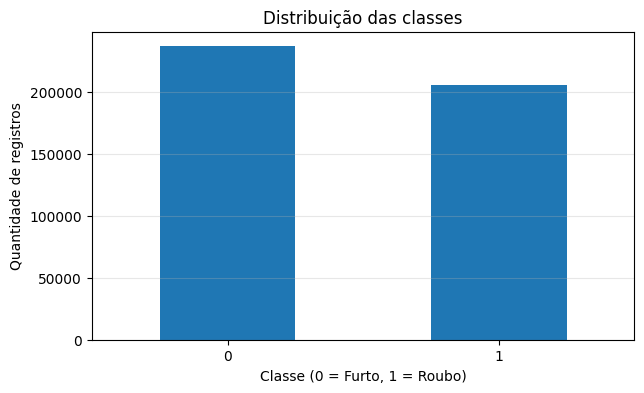

In [ ]:

# Quantidade de registros e distribuição das classes

print("Quantidade total de registros utilizados:", len(dados_modelo))
print("Quantidade de boletins únicos:", groups.nunique())

print("\nDistribuição das classes:")
distribuicao = y.value_counts().sort_index()

display(pd.DataFrame({
    "Classe": ["Furto (0)", "Roubo (1)"],
    "Quantidade": [
        distribuicao.get(0, 0),
        distribuicao.get(1, 0)
    ],
    "Percentual (%)": [
        y.value_counts(normalize=True).get(0, 0) * 100,
        y.value_counts(normalize=True).get(1, 0) * 100
    ]
}).round(2))

# Visualização da distribuição das classes
plt.figure(figsize=(7, 4))
y.value_counts().sort_index().plot(kind="bar")
plt.title("Distribuição das classes")
plt.xlabel("Classe (0 = Furto, 1 = Roubo)")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


## 8. Divisão em treinamento, validação e teste

A divisão será aproximadamente 70% para treinamento, 15% para validação e 15% para teste. Utilizamos `StratifiedGroupKFold` para preservar, tanto quanto possível, a proporção das classes e manter todas as linhas de um mesmo boletim no mesmo subconjunto.

O conjunto de teste ficará isolado até a avaliação final. A validação será utilizada para comparar as arquiteturas e selecionar o modelo.

In [ ]:

# Divisão dos dados em treinamento, validação e teste
# Mantém os registros de um mesmo boletim no mesmo subconjunto.

sgkf = StratifiedGroupKFold(
    n_splits=20,
    shuffle=True,
    random_state=SEED
)

folds = list(sgkf.split(X, y, groups=groups))

# Aproximadamente 70% para treino, 15% para validação e 15% para teste
idx_train = np.concatenate([folds[i][1] for i in range(6, 20)])
idx_val = np.concatenate([folds[i][1] for i in range(0, 3)])
idx_test = np.concatenate([folds[i][1] for i in range(3, 6)])

X_train, y_train = X.iloc[idx_train].copy(), y.iloc[idx_train].copy()
X_val, y_val = X.iloc[idx_val].copy(), y.iloc[idx_val].copy()
X_test, y_test = X.iloc[idx_test].copy(), y.iloc[idx_test].copy()

groups_train = groups.iloc[idx_train]
groups_val = groups.iloc[idx_val]
groups_test = groups.iloc[idx_test]

# Verifica se existem boletins compartilhados entre os subconjuntos
assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))

# Exibe o tamanho de cada conjunto
print("Tamanho dos conjuntos:")
print(f"Treinamento: {len(X_train)} registros ({len(X_train)/len(X):.2%})")
print(f"Validação:   {len(X_val)} registros ({len(X_val)/len(X):.2%})")
print(f"Teste:       {len(X_test)} registros ({len(X_test)/len(X):.2%})")

# Compara a distribuição das classes
distribuicao_splits = []

for nome, serie in [
    ("Treinamento", y_train),
    ("Validação", y_val),
    ("Teste", y_test)
]:
    distribuicao_splits.append({
        "Conjunto": nome,
        "Total": len(serie),
        "Furto (0)": int((serie == 0).sum()),
        "Roubo (1)": int((serie == 1).sum()),
        "Furto (%)": round((serie == 0).mean() * 100, 2),
        "Roubo (%)": round((serie == 1).mean() * 100, 2)
    })

display(pd.DataFrame(distribuicao_splits))

print("Verificação concluída: nenhum boletim aparece em mais de um conjunto.")


Tamanho dos conjuntos:
Treinamento: 309868 registros (70.00%)
Validação:   66402 registros (15.00%)
Teste:       66402 registros (15.00%)


,Conjunto,Total,Furto (0),Roubo (1),Furto (%),Roubo (%)
0,Treinamento,309868,165496,144372,53.41,46.59
1,Validação,66402,35635,30767,53.67,46.33
2,Teste,66402,35682,30720,53.74,46.26


Verificação concluída: nenhum boletim aparece em mais de um conjunto.


## 9. Pré-processamento das variáveis

As transformações são ajustadas exclusivamente com os dados de treinamento para evitar vazamento de informação.

- Variáveis numéricas: imputação pela mediana e padronização com `StandardScaler`.
- Variáveis categóricas: imputação pela categoria mais frequente e codificação one-hot.
- Categorias desconhecidas na validação ou no teste serão ignoradas pelo codificador.

Depois de ajustar o pré-processamento no treino, aplicamos a mesma transformação à validação e ao teste.

In [ ]:
numeric_features = ["MES", "LATITUDE", "LONGITUDE"]
categorical_features = ["CONDUTA", "NOME_DELEGACIA_CIRC"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Garante tipo compatível com TensorFlow
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)

print("Quantidade de atributos após o pré-processamento:", X_train_processed.shape[1])
print("Formato treino:", X_train_processed.shape)
print("Formato validação:", X_val_processed.shape)
print("Formato teste:", X_test_processed.shape)

Quantidade de atributos após o pré-processamento: 158
Formato treino: (309868, 158)
Formato validação: (66402, 158)
Formato teste: (66402, 158)



## 10. Implementação e configuração da MLP

Foi implementada uma rede neural do tipo Multilayer Perceptron (MLP), adequada para problemas de classificação binária.

A camada de entrada recebe a quantidade de atributos resultante do pré-processamento dos dados. As camadas ocultas utilizam neurônios densos (*Dense*) com função de ativação ReLU, que permite aprender relações não lineares entre as variáveis.

A camada de saída possui um único neurônio com função de ativação Sigmoid, responsável por produzir uma probabilidade entre 0 e 1 para a classe roubo.

**Configurações utilizadas:**

| Parâmetro | Configuração | Justificativa |
|---|---|---|
| Arquitetura | MLP | Adequada para classificação de dados tabulares. |
| Ativação oculta | ReLU | Permite aprender padrões não lineares e é computacionalmente eficiente. |
| Ativação de saída | Sigmoid | Produz uma probabilidade para classificação binária. |
| Função de perda | Binary Crossentropy | Indicada para problemas com duas classes. |
| Otimizador | Adam | Adapta as taxas de atualização dos pesos durante o treinamento. |
| Taxa de aprendizado | 0,001 | Valor inicial utilizado para uma convergência estável. |
| Épocas máximas | 40 | Define o limite de treinamento de cada arquitetura. |
| Batch size | 512 | Define a quantidade de amostras processadas em cada atualização dos pesos. |
| Early Stopping | Patience = 5 | Interrompe o treinamento quando a perda de validação deixa de melhorar. |

A utilização de Early Stopping ajuda a reduzir o risco de overfitting, restaurando os pesos da época com melhor resultado na validação.


In [ ]:
def criar_mlp(input_dim, camadas, learning_rate=0.001):
    modelo = tf.keras.Sequential()
    modelo.add(tf.keras.layers.Input(shape=(input_dim,)))

    for unidades in camadas:
        modelo.add(tf.keras.layers.Dense(unidades, activation="relu"))

    modelo.add(tf.keras.layers.Dense(1, activation="sigmoid"))

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )
    return modelo


arquiteturas = {
    "MLP 1 - 32 neurônios": [32],
    "MLP 2 - 64-32 neurônios": [64, 32],
    "MLP 3 - 128-64-32 neurônios": [128, 64, 32]
}

print("Experimentos definidos:", list(arquiteturas.keys()))

Experimentos definidos: ['MLP 1 - 32 neurônios', 'MLP 2 - 64-32 neurônios', 'MLP 3 - 128-64-32 neurônios']



## 11. Experimentos e treinamento das arquiteturas

Foram realizados três experimentos, variando a quantidade de camadas ocultas e o número de neurônios de cada arquitetura.

| Experimento | Camadas ocultas | Neurônios | Alteração realizada |
|---|---:|---|---|
| MLP 1 | 1 | 32 | Arquitetura inicial e mais simples. |
| MLP 2 | 2 | 64 e 32 | Aumento da capacidade de aprendizado com uma camada adicional. |
| MLP 3 | 3 | 128, 64 e 32 | Arquitetura mais profunda, com maior capacidade de representação. |

Para manter uma comparação controlada, os três modelos utilizam os mesmos dados de treinamento e validação, função de ativação, otimizador, taxa de aprendizado, função de perda e hiperparâmetros.

A única alteração principal entre os experimentos é a estrutura das camadas ocultas.

Após o treinamento, cada modelo será avaliado no conjunto de validação utilizando acurácia, precisão, recall e F1-score. Essas métricas permitirão analisar os efeitos do aumento da profundidade e da quantidade de neurônios no desempenho da classificação.

O conjunto de teste não será utilizado durante os experimentos nem durante a seleção da arquitetura.


In [ ]:
historicos = {}
modelos = {}
resultados_validacao = []

EPOCHS = 40
BATCH_SIZE = 512

for nome, camadas in arquiteturas.items():
    print("\n" + "=" * 65)
    print("Treinando:", nome)
    print("=" * 65)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    modelo = criar_mlp(
        input_dim=X_train_processed.shape[1],
        camadas=camadas,
        learning_rate=0.001
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    history = modelo.fit(
        X_train_processed,
        y_train_np,
        validation_data=(X_val_processed, y_val_np),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=1
    )

    modelos[nome] = modelo
    historicos[nome] = history

    probabilidades = modelo.predict(X_val_processed, verbose=0).ravel()
    previsoes = (probabilidades >= 0.5).astype(int)

    resultados_validacao.append({
        "Modelo": nome,
        "Épocas treinadas": len(history.history["loss"]),
        "Melhor val_loss": min(history.history["val_loss"]),
        "Accuracy": accuracy_score(y_val, previsoes),
        "Precision": precision_score(y_val, previsoes, zero_division=0),
        "Recall": recall_score(y_val, previsoes, zero_division=0),
        "F1-score": f1_score(y_val, previsoes, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilidades)
    })

tabela_validacao = pd.DataFrame(resultados_validacao).sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

display(tabela_validacao.round(4))


Treinando: MLP 1 - 32 neurônios
Epoch 1/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7257 - loss: 0.5450 - precision: 0.7050 - recall: 0.7071 - val_accuracy: 0.7476 - val_loss: 0.5142 - val_precision: 0.7369 - val_recall: 0.7082
Epoch 2/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7496 - loss: 0.5114 - precision: 0.7464 - recall: 0.7006 - val_accuracy: 0.7504 - val_loss: 0.5110 - val_precision: 0.7433 - val_recall: 0.7048
Epoch 3/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7515 - loss: 0.5090 - precision: 0.7496 - recall: 0.7008 - val_accuracy: 0.7516 - val_loss: 0.5094 - val_precision: 0.7447 - val_recall: 0.7059
Epoch 4/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7525 - loss: 0.5076 - precision: 0.7504 - recall: 0.7024 - val_accuracy: 0.7520 - val_loss: 0.5084 - val_precision: 0.7455 - val_recall: 0.7055
Epoch 5/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7532 - loss: 0.5066 - precision: 0.7509 - recall: 0.7037 - va

,Modelo,Épocas treinadas,Melhor val_loss,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,MLP 3 - 128-64-32 neurônios,35,0.5005,0.7599,0.7535,0.7163,0.7344,0.8348
1,MLP 2 - 64-32 neurônios,40,0.5016,0.7577,0.7474,0.7207,0.7338,0.8337
2,MLP 1 - 32 neurônios,40,0.5040,0.7554,0.7466,0.7146,0.7303,0.8317



## 12. Análise das curvas de treinamento e validação

As curvas de treinamento e validação permitem acompanhar a evolução do aprendizado das arquiteturas ao longo das épocas.

Serão analisadas duas métricas:

- **Acurácia (Accuracy):** representa a proporção de classificações corretas.
- **Perda (Loss):** representa o erro calculado pela função Binary Crossentropy.

A comparação entre treinamento e validação permite identificar possíveis problemas de generalização.

- **Overfitting:** ocorre quando o modelo apresenta melhora no treinamento, mas a validação deixa de melhorar ou piora. Uma diferença crescente entre as curvas pode indicar que o modelo está memorizando os dados de treinamento.
- **Underfitting:** ocorre quando o modelo apresenta desempenho baixo tanto no treinamento quanto na validação, indicando que não conseguiu aprender adequadamente os padrões dos dados.
- **Boa generalização:** ocorre quando as métricas de treinamento e validação apresentam resultados próximos e satisfatórios.

As curvas serão utilizadas para complementar a comparação das métricas e a escolha da arquitetura.


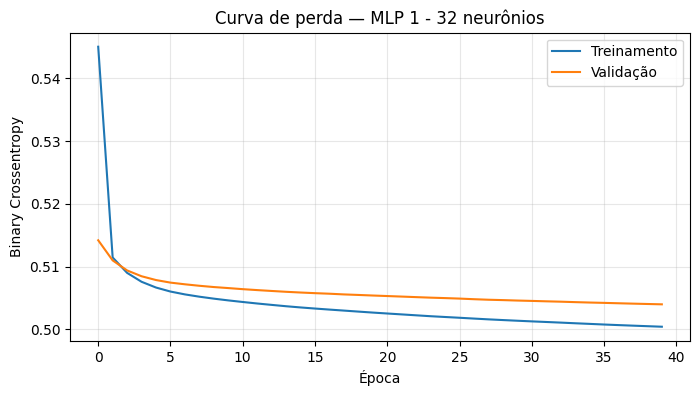

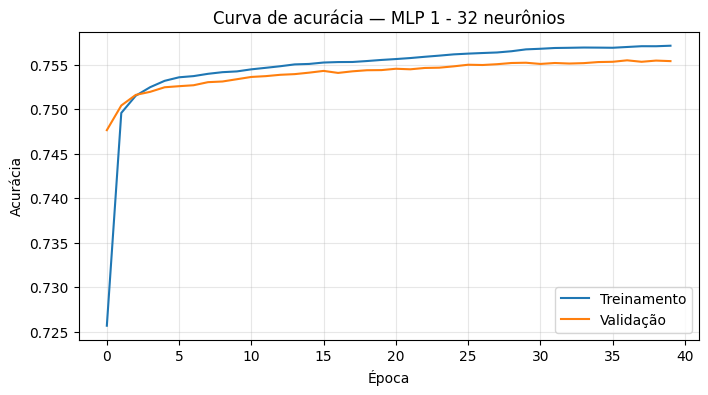

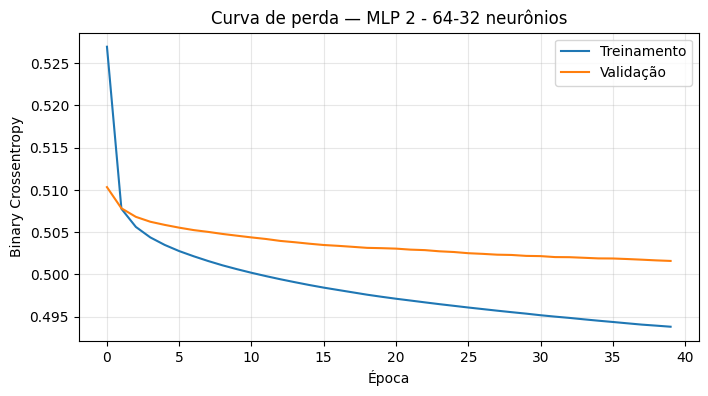

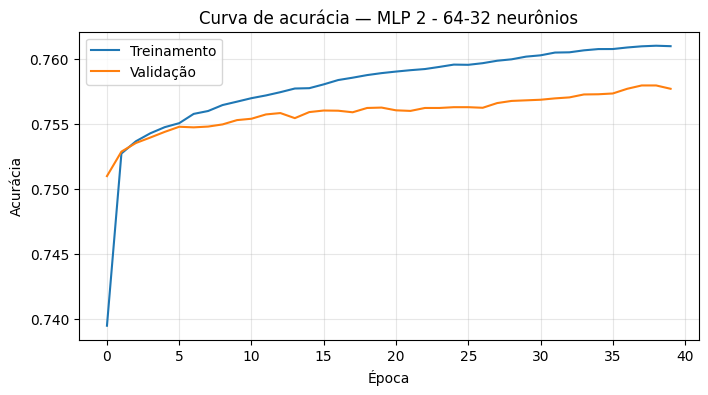

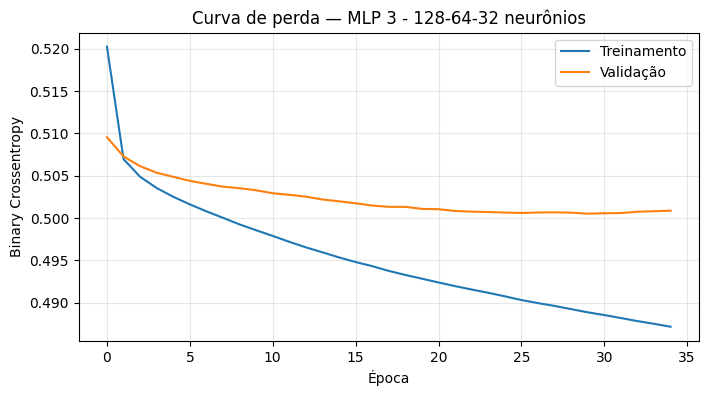

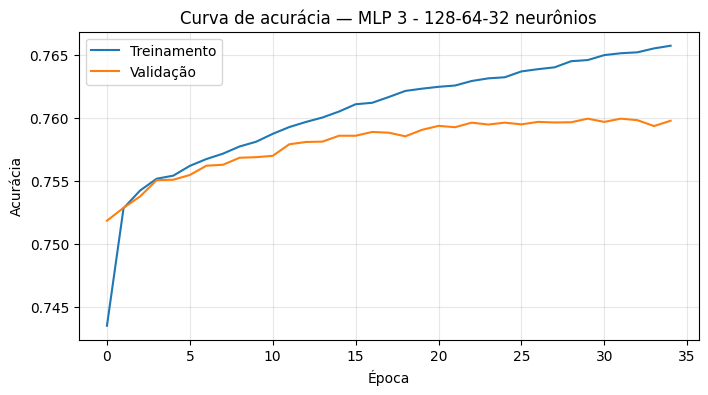

In [ ]:

# Gráficos de perda (Loss) e acurácia (Accuracy)
# Comparação entre treinamento e validação para cada arquitetura.

for nome, history in historicos.items():

    # Gráfico de perda
    plt.figure(figsize=(8, 4))

    plt.plot(
        history.history["loss"],
        label="Treinamento"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validação"
    )

    plt.title(f"Curva de perda — {nome}")
    plt.xlabel("Época")
    plt.ylabel("Binary Crossentropy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # Gráfico de acurácia
    plt.figure(figsize=(8, 4))

    plt.plot(
        history.history["accuracy"],
        label="Treinamento"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validação"
    )

    plt.title(f"Curva de acurácia — {nome}")
    plt.xlabel("Época")
    plt.ylabel("Acurácia")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()



## 13. Comparação e seleção da melhor arquitetura

As arquiteturas serão comparadas com base nos resultados obtidos no conjunto de validação.

As métricas utilizadas são:

- **Accuracy:** proporção total de classificações corretas.
- **Precision:** proporção de previsões positivas que realmente pertencem à classe roubo.
- **Recall:** proporção de ocorrências de roubo corretamente identificadas.
- **F1-score:** média harmônica entre precision e recall.

O F1-score será utilizado como critério principal de seleção, pois considera o equilíbrio entre precision e recall.

A arquitetura com maior F1-score na validação será selecionada. Em caso de resultados próximos, também serão consideradas a perda de validação e as curvas de aprendizado.

A seleção será realizada exclusivamente com os dados de validação. O conjunto de teste permanecerá isolado até a avaliação final.


In [ ]:
melhor_nome = tabela_validacao.iloc[0]["Modelo"]
melhor_modelo = modelos[melhor_nome]

print("Melhor arquitetura selecionada:", melhor_nome)
print("\nMétricas de validação:")
display(tabela_validacao.iloc[[0]].round(4))

Melhor arquitetura selecionada: MLP 3 - 128-64-32 neurônios

Métricas de validação:


,Modelo,Épocas treinadas,Melhor val_loss,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,MLP 3 - 128-64-32 neurônios,35,0.5005,0.7599,0.7535,0.7163,0.7344,0.8348


In [ ]:

# Análise de overfitting e underfitting da arquitetura selecionada

history_escolhido = historicos[melhor_nome]

loss_treino = history_escolhido.history["loss"]
loss_validacao = history_escolhido.history["val_loss"]

acc_treino = history_escolhido.history["accuracy"]
acc_validacao = history_escolhido.history["val_accuracy"]

# Identifica a época com menor perda de validação
melhor_epoca = int(np.argmin(loss_validacao))

print("Modelo selecionado:", melhor_nome)
print("Melhor época pela perda de validação:", melhor_epoca + 1)

print("\nResultados na melhor época:")
print(f"Loss de treinamento: {loss_treino[melhor_epoca]:.4f}")
print(f"Loss de validação:   {loss_validacao[melhor_epoca]:.4f}")
print(f"Accuracy de treino:  {acc_treino[melhor_epoca]:.4f}")
print(f"Accuracy de validação: {acc_validacao[melhor_epoca]:.4f}")

print("\nDiferença entre as métricas:")
print(
    "Diferença de loss:",
    round(loss_validacao[melhor_epoca] - loss_treino[melhor_epoca], 4)
)
print(
    "Diferença de accuracy:",
    round(acc_treino[melhor_epoca] - acc_validacao[melhor_epoca], 4)
)

print("\nÚltima época registrada:")
print(f"Loss de treinamento: {loss_treino[-1]:.4f}")
print(f"Loss de validação:   {loss_validacao[-1]:.4f}")
print(f"Accuracy de treino:  {acc_treino[-1]:.4f}")
print(f"Accuracy de validação: {acc_validacao[-1]:.4f}")


Modelo selecionado: MLP 3 - 128-64-32 neurônios
Melhor época pela perda de validação: 30

Resultados na melhor época:
Loss de treinamento: 0.4888
Loss de validação:   0.5005
Accuracy de treino:  0.7646
Accuracy de validação: 0.7599

Diferença entre as métricas:
Diferença de loss: 0.0117
Diferença de accuracy: 0.0047

Última época registrada:
Loss de treinamento: 0.4871
Loss de validação:   0.5009
Accuracy de treino:  0.7657
Accuracy de validação: 0.7598


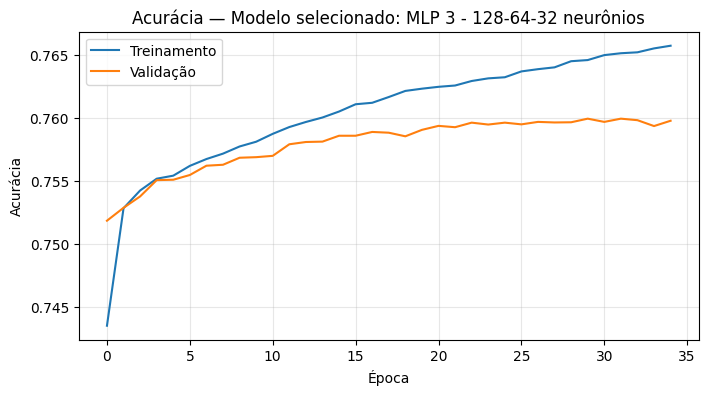

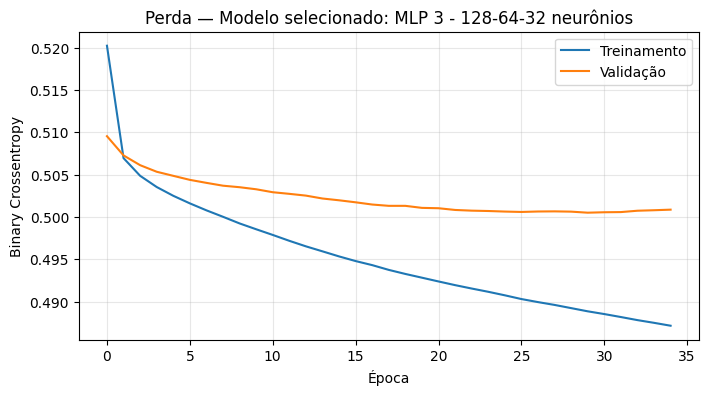

In [ ]:

# Curvas de aprendizado da arquitetura selecionada

history_escolhido = historicos[melhor_nome]

# Acurácia
plt.figure(figsize=(8, 4))
plt.plot(history_escolhido.history["accuracy"], label="Treinamento")
plt.plot(history_escolhido.history["val_accuracy"], label="Validação")
plt.title(f"Acurácia — Modelo selecionado: {melhor_nome}")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Perda
plt.figure(figsize=(8, 4))
plt.plot(history_escolhido.history["loss"], label="Treinamento")
plt.plot(history_escolhido.history["val_loss"], label="Validação")
plt.title(f"Perda — Modelo selecionado: {melhor_nome}")
plt.xlabel("Época")
plt.ylabel("Binary Crossentropy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



## 14. Avaliação final no conjunto de teste

Após a seleção da melhor arquitetura com base nos resultados de validação, o modelo será avaliado no conjunto de teste.

O conjunto de teste não participou do treinamento, do ajuste dos hiperparâmetros ou da seleção da arquitetura. Dessa forma, seus resultados fornecem uma avaliação final do desempenho do modelo em registros não utilizados nas etapas anteriores.

O limiar de classificação será 0,5:

- Probabilidade igual ou superior a 0,5: classificação como roubo (1).
- Probabilidade inferior a 0,5: classificação como furto (0).

Serão apresentadas as métricas accuracy, precision, recall e F1-score, além da matriz de confusão e do relatório de classificação.


Modelo avaliado: MLP 3 - 128-64-32 neurônios


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Log Loss
0,0.7594,0.7519,0.7161,0.7336,0.8346,0.5015



Relatório de classificação:
              precision    recall  f1-score   support

   Furto (0)       0.77      0.80      0.78     35682
   Roubo (1)       0.75      0.72      0.73     30720

    accuracy                           0.76     66402
   macro avg       0.76      0.76      0.76     66402
weighted avg       0.76      0.76      0.76     66402



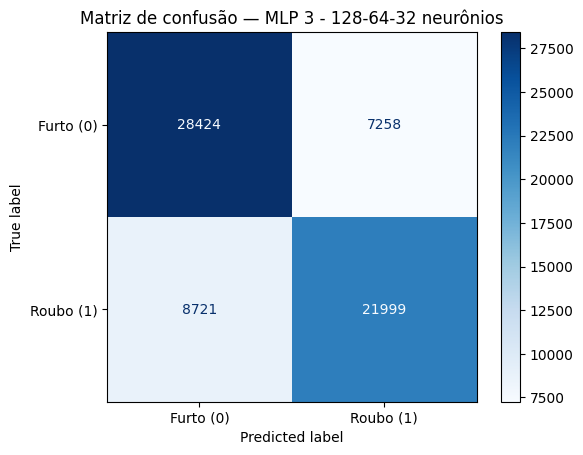

In [ ]:
prob_test = melhor_modelo.predict(X_test_processed, verbose=0).ravel()
pred_test = (prob_test >= 0.5).astype(int)

metricas_teste = {
    "Accuracy": accuracy_score(y_test, pred_test),
    "Precision": precision_score(y_test, pred_test, zero_division=0),
    "Recall": recall_score(y_test, pred_test, zero_division=0),
    "F1-score": f1_score(y_test, pred_test, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, prob_test),
    "Log Loss": log_loss(y_test, prob_test)
}

print("Modelo avaliado:", melhor_nome)
display(pd.DataFrame([metricas_teste]).round(4))

print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    pred_test,
    target_names=["Furto (0)", "Roubo (1)"],
    zero_division=0
))

cm = confusion_matrix(y_test, pred_test)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Furto (0)", "Roubo (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Matriz de confusão — {melhor_nome}")
plt.show()


## 15. Interpretação dos resultados

Nesta etapa, serão interpretados os resultados da avaliação final no conjunto de teste.

A matriz de confusão permite identificar:

- Verdadeiros positivos: ocorrências de roubo corretamente classificadas como roubo.
- Verdadeiros negativos: ocorrências de furto corretamente classificadas como furto.
- Falsos positivos: ocorrências de furto classificadas incorretamente como roubo.
- Falsos negativos: ocorrências de roubo classificadas incorretamente como furto.

A análise também deverá considerar as métricas accuracy, precision, recall e F1-score.

**Análise do aprendizado:**

Com base nas curvas de treinamento e validação, será avaliado se a arquitetura selecionada apresentou sinais de overfitting, underfitting ou boa generalização.

**Comparação dos experimentos:**

Os resultados de validação das três arquiteturas serão comparados para identificar se o aumento da quantidade de camadas e neurônios trouxe melhorias no desempenho.

**Conclusão da avaliação:**

Os resultados do conjunto de teste serão utilizados para discutir a capacidade de classificação do modelo e suas limitações. A análise deverá considerar que os dados representam ocorrências registradas em 2016 e que o modelo não prevê crimes futuros nem estima risco criminal.


## 16. Salvamento do modelo e do pré-processador

Salvamos a rede neural selecionada e o pré-processador ajustado no conjunto de treinamento. Os dois artefatos são necessários para reproduzir as previsões: o modelo recebe os dados já transformados, portanto o pré-processador deve ser utilizado exatamente como foi treinado.

In [ ]:
import joblib

melhor_modelo.save("modelo_mlp_furto_roubo.keras")
joblib.dump(preprocessor, "preprocessador_furto_roubo.joblib")

print("Modelo e pré-processador salvos.")

Modelo e pré-processador salvos.


## 17. Download dos artefatos

Esta célula disponibiliza os arquivos treinados para download no computador. Eles poderão ser utilizados posteriormente na aplicação web, desde que a aplicação reproduza as mesmas colunas e o mesmo pré-processamento.

In [ ]:
from google.colab import files

files.download("modelo_mlp_furto_roubo.keras")
files.download("preprocessador_furto_roubo.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. Conclusão

Neste trabalho, foi desenvolvido um classificador binário baseado em MLP para diferenciar registros classificados como furto e roubo no município de São Paulo, considerando dados de 2016. Foram comparadas três arquiteturas com diferentes profundidades, utilizando validação para selecionar o modelo e um conjunto de teste isolado para a avaliação final.

A conclusão deve informar: (1) qual arquitetura obteve o melhor F1-score na validação; (2) quais foram as métricas finais no teste; (3) quais erros aparecem na matriz de confusão; e (4) quais limitações impedem generalizar os resultados para outros anos ou contextos.

**Limitações:** os dados são registros administrativos de 2016; as categorias dependem da classificação registrada; as coordenadas possuem valores ausentes; e as variáveis territoriais/contextuais podem refletir padrões locais. O desempenho não demonstra causalidade, não prevê a ocorrência futura de crimes e não deve ser interpretado como avaliação de segurança de pessoas ou bairros.